In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime


import common

%load_ext autoreload
%autoreload 2



In [2]:
ts_msgs = pd.read_csv("../2025-12-19_10-50-09/pg2gw/ts_msgs_with_gt.csv")
ts_msgs['timestamp'] = pd.to_datetime(ts_msgs['timestamp'])
ts_msgs

,timestamp,device_id,detection,filtered_confidence,filtered_novelty,all,gt_value
0,2025-12-19 10:00:00+00:00,6000000-2000-000003-2550,0,1,0,1,1
1,2025-12-19 10:00:11+00:00,6000000-2000-000003-2550,0,1,0,1,1
2,2025-12-19 10:00:22+00:00,6000000-2000-000003-2550,0,0,1,1,1
3,2025-12-19 10:00:33+00:00,6000000-2000-000003-2550,0,1,0,1,1
4,2025-12-19 10:00:44+00:00,6000000-2000-000003-2550,0,1,0,1,1
...,...,...,...,...,...,...,...
218,2025-12-19 10:47:15+00:00,6000000-2000-000009-2550,1,0,0,1,1
219,2025-12-19 10:47:26+00:00,6000000-2000-000009-2550,1,0,0,1,1
220,2025-12-19 10:47:37+00:00,6000000-2000-000009-2550,0,1,0,1,1
221,2025-12-19 10:47:48+00:00,6000000-2000-000009-2550,0,1,0,1,1


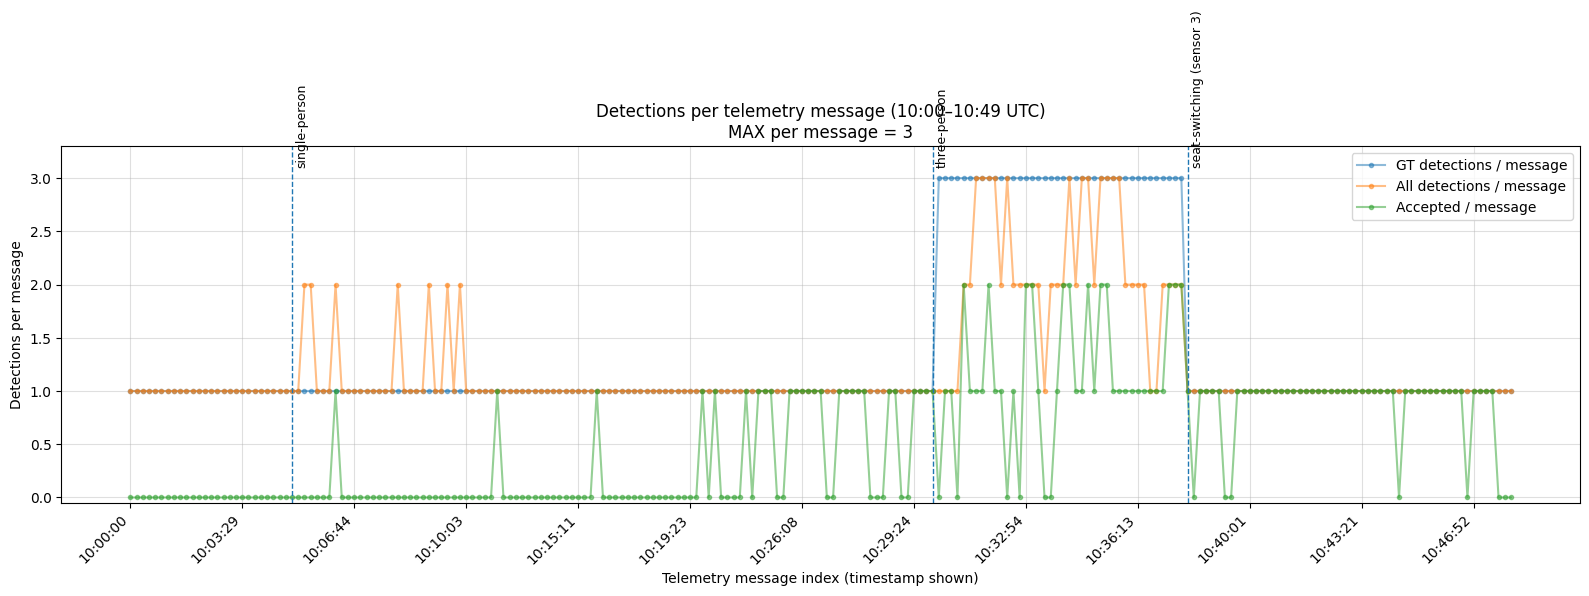

In [3]:
# ------------------------------------------------------------
# 6) Plot + vertical split lines (using timestamps from common.py)
# ------------------------------------------------------------
plt.figure(figsize=(16, 6))

x = np.arange(len(ts_msgs))
labels = ts_msgs["timestamp"].dt.strftime("%H:%M:%S").tolist()

plt.plot(x, ts_msgs["gt_value"], ".-", alpha=0.5, label="GT detections / message")
plt.plot(x, ts_msgs["all"], ".-", alpha=0.5, label="All detections / message")
plt.plot(x, ts_msgs["detection"], ".-", alpha=0.5, label="Accepted / message")

# Get the date from the first timestamp
base_date = ts_msgs["timestamp"].iloc[0].date()

# Convert time constants from common.py to full datetimes
splits = [
    (datetime.combine(base_date, common.ONE_PERSON_START).replace(tzinfo=ts_msgs["timestamp"].iloc[0].tzinfo), "single-person", "10:05"),
    (datetime.combine(base_date, common.THREE_PERSONS_START).replace(tzinfo=ts_msgs["timestamp"].iloc[0].tzinfo), "three-person", "10:30"),
    (datetime.combine(base_date, common.ONE_PERSON_CHAIRS_START).replace(tzinfo=ts_msgs["timestamp"].iloc[0].tzinfo), "seat-switching (sensor 3)", "10:38"),
]

# Draw vertical lines at split timestamps
ymax = float(ts_msgs[["all", "detection", "filtered_confidence", "filtered_novelty"]].to_numpy().max())
y_text = ymax + 0.1  # small headroom for labels

ts_series = ts_msgs["timestamp"].reset_index(drop=True)
for split_time, label, hhmm in splits:
    # Find the index of the closest timestamp
    diffs = (ts_series - split_time).abs()
    idx = int(diffs.idxmin())
    
    plt.axvline(idx, linestyle="--", linewidth=1)
    # Put text near top
    plt.text(idx + 0.5, y_text, f"{label}", rotation=90, va="bottom", ha="left", fontsize=9)

# x ticks formatting
step = max(1, len(x) // 12)
plt.xticks(
    ticks=np.arange(0, len(x), step),
    labels=[labels[i] for i in range(0, len(x), step)],
    rotation=45,
    ha="right"
)

plt.xlabel("Telemetry message index (timestamp shown)")
plt.ylabel("Detections per message")
plt.title(
    f"Detections per telemetry message (10:00–10:49 UTC)\n"
    f"MAX per message = {int(ts_msgs['all'].max())}"
)
plt.ylim(bottom=-0.05, top=y_text + 0.2)
plt.legend()
plt.grid(alpha=0.4)
plt.tight_layout()
plt.show()

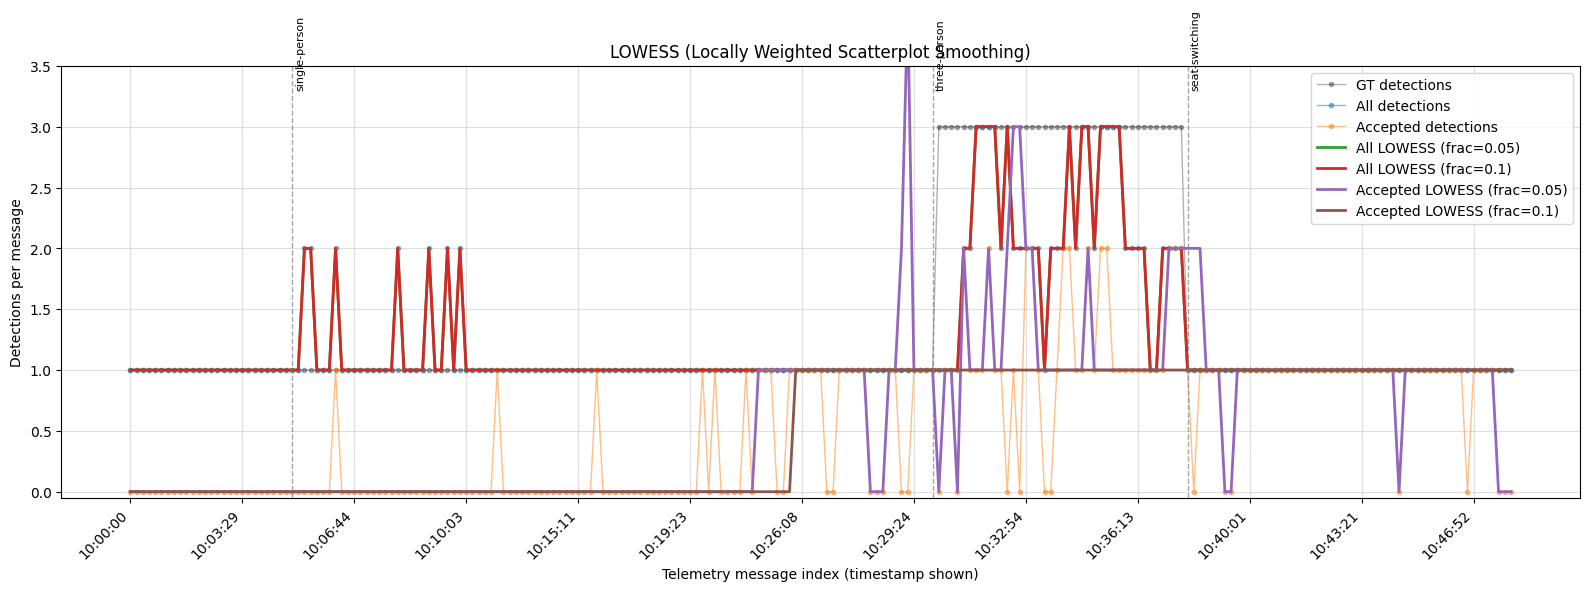

In [4]:
# ------------------------------------------------------------
# LOWESS (Locally Weighted Scatterplot Smoothing)
# ------------------------------------------------------------
plt.figure(figsize=(16, 6))

x = np.arange(len(ts_msgs))
labels = ts_msgs["timestamp"].dt.strftime("%H:%M:%S").tolist()

# Base lines
plt.plot(x, ts_msgs["gt_value"], "k.-", alpha=0.3, label="GT detections", linewidth=1)
plt.plot(x, ts_msgs["all"], ".-", alpha=0.5, label="All detections", linewidth=1)
plt.plot(x, ts_msgs["detection"], ".-", alpha=0.5, label="Accepted detections", linewidth=1)

# Smoothed lines (frac controls smoothing, smaller = less smooth)
all_smooth_3 = np.round(common.lowess(ts_msgs["all"].values, frac=0.05)).astype(int)
all_smooth_5 = np.round(common.lowess(ts_msgs["all"].values, frac=0.1)).astype(int)
det_smooth_3 = np.round(common.lowess(ts_msgs["detection"].values, frac=0.05)).astype(int)
det_smooth_5 = np.round(common.lowess(ts_msgs["detection"].values, frac=0.1)).astype(int)

plt.plot(x, all_smooth_3, "-", linewidth=2, label="All LOWESS (frac=0.05)")
plt.plot(x, all_smooth_5, "-", linewidth=2, label="All LOWESS (frac=0.1)")
plt.plot(x, det_smooth_3, "-", linewidth=2, label="Accepted LOWESS (frac=0.05)")
plt.plot(x, det_smooth_5, "-", linewidth=2, label="Accepted LOWESS (frac=0.1)")

# Vertical split lines
base_date = ts_msgs["timestamp"].iloc[0].date()
splits = [
    (datetime.combine(base_date, common.ONE_PERSON_START).replace(tzinfo=ts_msgs["timestamp"].iloc[0].tzinfo), "single-person"),
    (datetime.combine(base_date, common.THREE_PERSONS_START).replace(tzinfo=ts_msgs["timestamp"].iloc[0].tzinfo), "three-person"),
    (datetime.combine(base_date, common.ONE_PERSON_CHAIRS_START).replace(tzinfo=ts_msgs["timestamp"].iloc[0].tzinfo), "seat-switching"),
]

ymax = 3.5
ts_series = ts_msgs["timestamp"].reset_index(drop=True)
for split_time, label in splits:
    diffs = (ts_series - split_time).abs()
    idx = int(diffs.idxmin())
    plt.axvline(idx, linestyle="--", linewidth=1, color="gray", alpha=0.7)
    plt.text(idx + 0.5, ymax - 0.2, label, rotation=90, va="bottom", ha="left", fontsize=8)

step = max(1, len(x) // 12)
plt.xticks(ticks=np.arange(0, len(x), step), labels=[labels[i] for i in range(0, len(x), step)], rotation=45, ha="right")
plt.xlabel("Telemetry message index (timestamp shown)")
plt.ylabel("Detections per message")
plt.title("LOWESS (Locally Weighted Scatterplot Smoothing)")
plt.ylim(bottom=-0.05, top=ymax)
plt.legend(loc='upper right')
plt.grid(alpha=0.4)
plt.tight_layout()
plt.show()

In [5]:
# ------------------------------------------------------------
# Comparison Table: MAE and MSE vs GT
# ------------------------------------------------------------
from sklearn.metrics import mean_absolute_error, mean_squared_error

results = []

# Ground truth
gt = ts_msgs["gt_value"].values

# Raw data (no smoothing)
results.append({
    'Method': 'No Smoothing',
    'Signal': 'All',
    'Params': '-',
    'MAE': mean_absolute_error(gt, ts_msgs["all"].values),
    'MSE': mean_squared_error(gt, ts_msgs["all"].values)
})
results.append({
    'Method': 'No Smoothing',
    'Signal': 'Accepted',
    'Params': '-',
    'MAE': mean_absolute_error(gt, ts_msgs["detection"].values),
    'MSE': mean_squared_error(gt, ts_msgs["detection"].values)
})

# SMA
for window in [3, 5]:
    all_smooth = np.round(common.sma(ts_msgs["all"].values, window=window)).astype(int)
    det_smooth = np.round(common.sma(ts_msgs["detection"].values, window=window)).astype(int)
    results.append({
        'Method': 'SMA',
        'Signal': 'All',
        'Params': f'w={window}',
        'MAE': mean_absolute_error(gt, all_smooth),
        'MSE': mean_squared_error(gt, all_smooth)
    })
    results.append({
        'Method': 'SMA',
        'Signal': 'Accepted',
        'Params': f'w={window}',
        'MAE': mean_absolute_error(gt, det_smooth),
        'MSE': mean_squared_error(gt, det_smooth)
    })

# WMA
for window in [3, 5]:
    all_smooth = np.round(common.wma(ts_msgs["all"].values, window=window)).astype(int)
    det_smooth = np.round(common.wma(ts_msgs["detection"].values, window=window)).astype(int)
    results.append({
        'Method': 'WMA',
        'Signal': 'All',
        'Params': f'w={window}',
        'MAE': mean_absolute_error(gt, all_smooth),
        'MSE': mean_squared_error(gt, all_smooth)
    })
    results.append({
        'Method': 'WMA',
        'Signal': 'Accepted',
        'Params': f'w={window}',
        'MAE': mean_absolute_error(gt, det_smooth),
        'MSE': mean_squared_error(gt, det_smooth)
    })

# EMA
for alpha in [0.3, 0.2]:
    all_smooth = np.round(common.ema(ts_msgs["all"].values, alpha=alpha)).astype(int)
    det_smooth = np.round(common.ema(ts_msgs["detection"].values, alpha=alpha)).astype(int)
    results.append({
        'Method': 'EMA',
        'Signal': 'All',
        'Params': f'α={alpha}',
        'MAE': mean_absolute_error(gt, all_smooth),
        'MSE': mean_squared_error(gt, all_smooth)
    })
    results.append({
        'Method': 'EMA',
        'Signal': 'Accepted',
        'Params': f'α={alpha}',
        'MAE': mean_absolute_error(gt, det_smooth),
        'MSE': mean_squared_error(gt, det_smooth)
    })

# Gaussian
for sigma in [1.0, 1.5]:
    all_smooth = np.round(common.gaussian_smooth(ts_msgs["all"].values, sigma=sigma)).astype(int)
    det_smooth = np.round(common.gaussian_smooth(ts_msgs["detection"].values, sigma=sigma)).astype(int)
    results.append({
        'Method': 'Gaussian',
        'Signal': 'All',
        'Params': f'σ={sigma}',
        'MAE': mean_absolute_error(gt, all_smooth),
        'MSE': mean_squared_error(gt, all_smooth)
    })
    results.append({
        'Method': 'Gaussian',
        'Signal': 'Accepted',
        'Params': f'σ={sigma}',
        'MAE': mean_absolute_error(gt, det_smooth),
        'MSE': mean_squared_error(gt, det_smooth)
    })

# Median
for window in [3, 5]:
    all_smooth = np.round(common.median_filter(ts_msgs["all"].values, window=window)).astype(int)
    det_smooth = np.round(common.median_filter(ts_msgs["detection"].values, window=window)).astype(int)
    results.append({
        'Method': 'Median',
        'Signal': 'All',
        'Params': f'w={window}',
        'MAE': mean_absolute_error(gt, all_smooth),
        'MSE': mean_squared_error(gt, all_smooth)
    })
    results.append({
        'Method': 'Median',
        'Signal': 'Accepted',
        'Params': f'w={window}',
        'MAE': mean_absolute_error(gt, det_smooth),
        'MSE': mean_squared_error(gt, det_smooth)
    })

# Savgol
params_list = [(3, 1), (5, 2)]
for window, polyorder in params_list:
    all_smooth = np.round(common.savgol(ts_msgs["all"].values, window=window, polyorder=polyorder)).astype(int)
    det_smooth = np.round(common.savgol(ts_msgs["detection"].values, window=window, polyorder=polyorder)).astype(int)
    results.append({
        'Method': 'Savgol',
        'Signal': 'All',
        'Params': f'w={window},p={polyorder}',
        'MAE': mean_absolute_error(gt, all_smooth),
        'MSE': mean_squared_error(gt, all_smooth)
    })
    results.append({
        'Method': 'Savgol',
        'Signal': 'Accepted',
        'Params': f'w={window},p={polyorder}',
        'MAE': mean_absolute_error(gt, det_smooth),
        'MSE': mean_squared_error(gt, det_smooth)
    })

# LOWESS
for frac in [0.05, 0.1]:
    all_smooth = np.round(common.lowess(ts_msgs["all"].values, frac=frac)).astype(int)
    det_smooth = np.round(common.lowess(ts_msgs["detection"].values, frac=frac)).astype(int)
    results.append({
        'Method': 'LOWESS',
        'Signal': 'All',
        'Params': f'frac={frac}',
        'MAE': mean_absolute_error(gt, all_smooth),
        'MSE': mean_squared_error(gt, all_smooth)
    })
    results.append({
        'Method': 'LOWESS',
        'Signal': 'Accepted',
        'Params': f'frac={frac}',
        'MAE': mean_absolute_error(gt, det_smooth),
        'MSE': mean_squared_error(gt, det_smooth)
    })

# Create DataFrame and sort by MAE
comparison_df = pd.DataFrame(results)
comparison_df = comparison_df.sort_values('MAE')
comparison_df = comparison_df.round(4)

print("Comparison of Smoothing Methods vs Ground Truth")
print("=" * 70)
display(comparison_df)

print("\n\nTop 5 Methods by MAE:")
print("=" * 70)
display(comparison_df.head(5))

Comparison of Smoothing Methods vs Ground Truth


,Method,Signal,Params,MAE,MSE
4,SMA,All,w=5,0.1390,0.1749
20,Median,All,w=5,0.1390,0.1749
16,Gaussian,All,σ=1.5,0.1390,0.1749
14,Gaussian,All,σ=1.0,0.1570,0.2108
2,SMA,All,w=3,0.1614,0.2152
24,Savgol,All,"w=5,p=2",0.1614,0.2152
22,Savgol,All,"w=3,p=1",0.1614,0.2152
18,Median,All,w=3,0.1614,0.2152
8,WMA,All,w=5,0.1659,0.2197
10,EMA,All,α=0.3,0.1794,0.2242




Top 5 Methods by MAE:


,Method,Signal,Params,MAE,MSE
4,SMA,All,w=5,0.1390,0.1749
20,Median,All,w=5,0.1390,0.1749
16,Gaussian,All,σ=1.5,0.1390,0.1749
14,Gaussian,All,σ=1.0,0.1570,0.2108
2,SMA,All,w=3,0.1614,0.2152


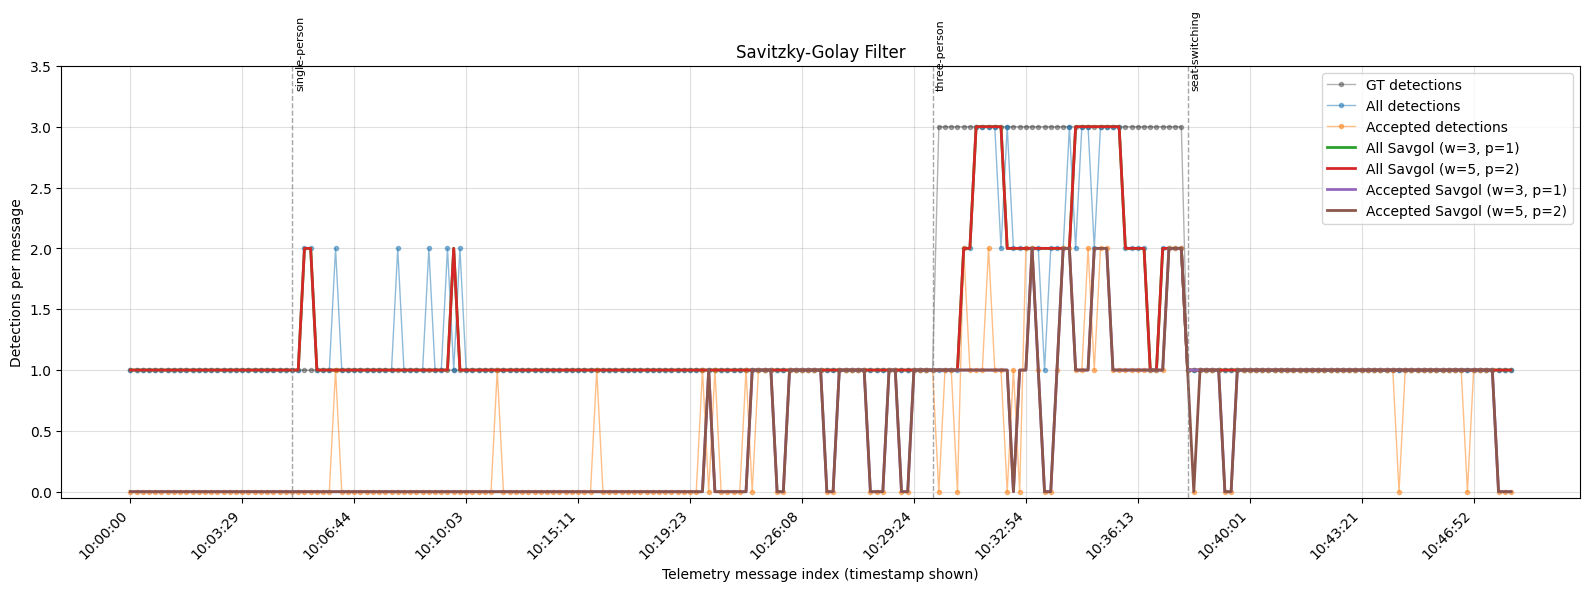

In [6]:
# ------------------------------------------------------------
# Savitzky-Golay Filter
# ------------------------------------------------------------
plt.figure(figsize=(16, 6))

x = np.arange(len(ts_msgs))
labels = ts_msgs["timestamp"].dt.strftime("%H:%M:%S").tolist()

# Base lines
plt.plot(x, ts_msgs["gt_value"], "k.-", alpha=0.3, label="GT detections", linewidth=1)
plt.plot(x, ts_msgs["all"], ".-", alpha=0.5, label="All detections", linewidth=1)
plt.plot(x, ts_msgs["detection"], ".-", alpha=0.5, label="Accepted detections", linewidth=1)

# Smoothed lines (window must be odd)
all_smooth_3 = np.round(common.savgol(ts_msgs["all"].values, window=3, polyorder=1)).astype(int)
all_smooth_5 = np.round(common.savgol(ts_msgs["all"].values, window=5, polyorder=2)).astype(int)
det_smooth_3 = np.round(common.savgol(ts_msgs["detection"].values, window=3, polyorder=1)).astype(int)
det_smooth_5 = np.round(common.savgol(ts_msgs["detection"].values, window=5, polyorder=2)).astype(int)

plt.plot(x, all_smooth_3, "-", linewidth=2, label="All Savgol (w=3, p=1)")
plt.plot(x, all_smooth_5, "-", linewidth=2, label="All Savgol (w=5, p=2)")
plt.plot(x, det_smooth_3, "-", linewidth=2, label="Accepted Savgol (w=3, p=1)")
plt.plot(x, det_smooth_5, "-", linewidth=2, label="Accepted Savgol (w=5, p=2)")

# Vertical split lines
base_date = ts_msgs["timestamp"].iloc[0].date()
splits = [
    (datetime.combine(base_date, common.ONE_PERSON_START).replace(tzinfo=ts_msgs["timestamp"].iloc[0].tzinfo), "single-person"),
    (datetime.combine(base_date, common.THREE_PERSONS_START).replace(tzinfo=ts_msgs["timestamp"].iloc[0].tzinfo), "three-person"),
    (datetime.combine(base_date, common.ONE_PERSON_CHAIRS_START).replace(tzinfo=ts_msgs["timestamp"].iloc[0].tzinfo), "seat-switching"),
]

ymax = 3.5
ts_series = ts_msgs["timestamp"].reset_index(drop=True)
for split_time, label in splits:
    diffs = (ts_series - split_time).abs()
    idx = int(diffs.idxmin())
    plt.axvline(idx, linestyle="--", linewidth=1, color="gray", alpha=0.7)
    plt.text(idx + 0.5, ymax - 0.2, label, rotation=90, va="bottom", ha="left", fontsize=8)

step = max(1, len(x) // 12)
plt.xticks(ticks=np.arange(0, len(x), step), labels=[labels[i] for i in range(0, len(x), step)], rotation=45, ha="right")
plt.xlabel("Telemetry message index (timestamp shown)")
plt.ylabel("Detections per message")
plt.title("Savitzky-Golay Filter")
plt.ylim(bottom=-0.05, top=ymax)
plt.legend(loc='upper right')
plt.grid(alpha=0.4)
plt.tight_layout()
plt.show()

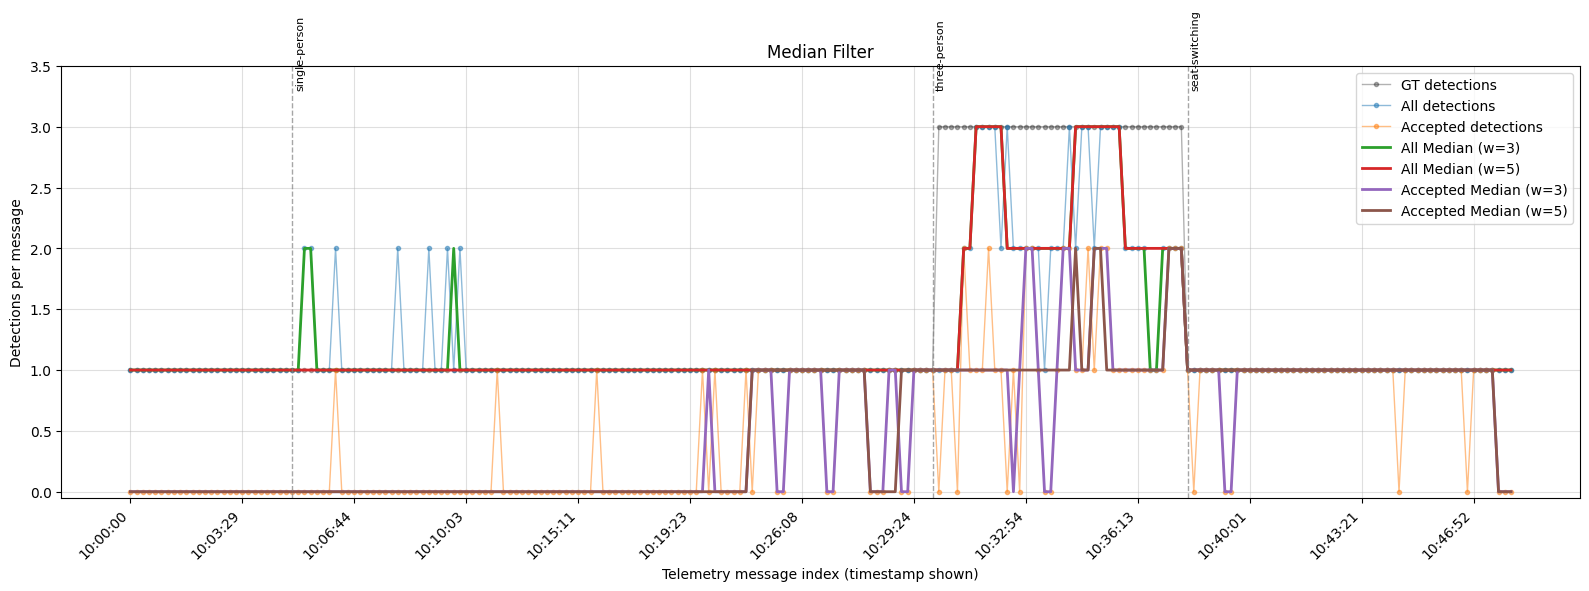

In [7]:
# ------------------------------------------------------------
# Median Filter
# ------------------------------------------------------------
plt.figure(figsize=(16, 6))

x = np.arange(len(ts_msgs))
labels = ts_msgs["timestamp"].dt.strftime("%H:%M:%S").tolist()

# Base lines
plt.plot(x, ts_msgs["gt_value"], "k.-", alpha=0.3, label="GT detections", linewidth=1)
plt.plot(x, ts_msgs["all"], ".-", alpha=0.5, label="All detections", linewidth=1)
plt.plot(x, ts_msgs["detection"], ".-", alpha=0.5, label="Accepted detections", linewidth=1)

# Smoothed lines
all_smooth_3 = np.round(common.median_filter(ts_msgs["all"].values, window=3)).astype(int)
all_smooth_5 = np.round(common.median_filter(ts_msgs["all"].values, window=5)).astype(int)
det_smooth_3 = np.round(common.median_filter(ts_msgs["detection"].values, window=3)).astype(int)
det_smooth_5 = np.round(common.median_filter(ts_msgs["detection"].values, window=5)).astype(int)

plt.plot(x, all_smooth_3, "-", linewidth=2, label="All Median (w=3)")
plt.plot(x, all_smooth_5, "-", linewidth=2, label="All Median (w=5)")
plt.plot(x, det_smooth_3, "-", linewidth=2, label="Accepted Median (w=3)")
plt.plot(x, det_smooth_5, "-", linewidth=2, label="Accepted Median (w=5)")

# Vertical split lines
base_date = ts_msgs["timestamp"].iloc[0].date()
splits = [
    (datetime.combine(base_date, common.ONE_PERSON_START).replace(tzinfo=ts_msgs["timestamp"].iloc[0].tzinfo), "single-person"),
    (datetime.combine(base_date, common.THREE_PERSONS_START).replace(tzinfo=ts_msgs["timestamp"].iloc[0].tzinfo), "three-person"),
    (datetime.combine(base_date, common.ONE_PERSON_CHAIRS_START).replace(tzinfo=ts_msgs["timestamp"].iloc[0].tzinfo), "seat-switching"),
]

ymax = 3.5
ts_series = ts_msgs["timestamp"].reset_index(drop=True)
for split_time, label in splits:
    diffs = (ts_series - split_time).abs()
    idx = int(diffs.idxmin())
    plt.axvline(idx, linestyle="--", linewidth=1, color="gray", alpha=0.7)
    plt.text(idx + 0.5, ymax - 0.2, label, rotation=90, va="bottom", ha="left", fontsize=8)

step = max(1, len(x) // 12)
plt.xticks(ticks=np.arange(0, len(x), step), labels=[labels[i] for i in range(0, len(x), step)], rotation=45, ha="right")
plt.xlabel("Telemetry message index (timestamp shown)")
plt.ylabel("Detections per message")
plt.title("Median Filter")
plt.ylim(bottom=-0.05, top=ymax)
plt.legend(loc='upper right')
plt.grid(alpha=0.4)
plt.tight_layout()
plt.show()

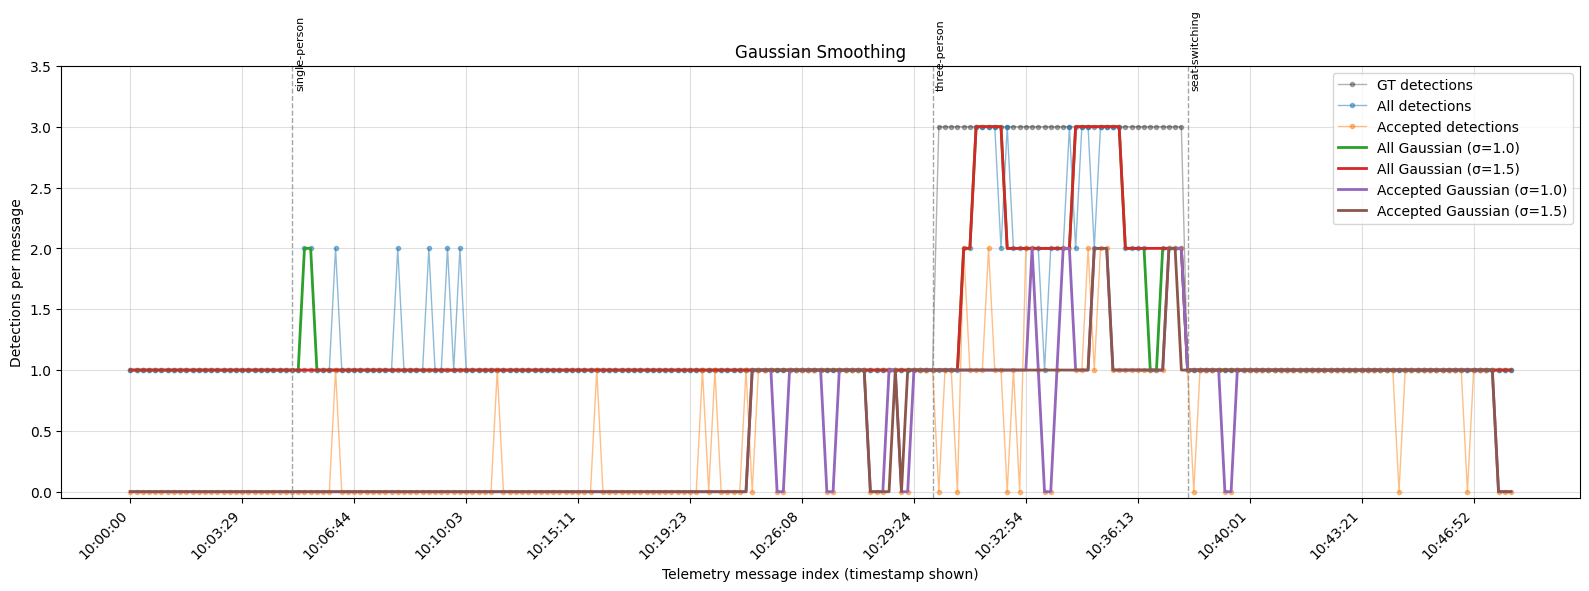

In [8]:
# ------------------------------------------------------------
# Gaussian Smoothing
# ------------------------------------------------------------
plt.figure(figsize=(16, 6))

x = np.arange(len(ts_msgs))
labels = ts_msgs["timestamp"].dt.strftime("%H:%M:%S").tolist()

# Base lines
plt.plot(x, ts_msgs["gt_value"], "k.-", alpha=0.3, label="GT detections", linewidth=1)
plt.plot(x, ts_msgs["all"], ".-", alpha=0.5, label="All detections", linewidth=1)
plt.plot(x, ts_msgs["detection"], ".-", alpha=0.5, label="Accepted detections", linewidth=1)

# Smoothed lines (sigma=1 ~= window 3, sigma=1.5 ~= window 5)
all_smooth_3 = np.round(common.gaussian_smooth(ts_msgs["all"].values, sigma=1.0)).astype(int)
all_smooth_5 = np.round(common.gaussian_smooth(ts_msgs["all"].values, sigma=1.5)).astype(int)
det_smooth_3 = np.round(common.gaussian_smooth(ts_msgs["detection"].values, sigma=1.0)).astype(int)
det_smooth_5 = np.round(common.gaussian_smooth(ts_msgs["detection"].values, sigma=1.5)).astype(int)

plt.plot(x, all_smooth_3, "-", linewidth=2, label="All Gaussian (σ=1.0)")
plt.plot(x, all_smooth_5, "-", linewidth=2, label="All Gaussian (σ=1.5)")
plt.plot(x, det_smooth_3, "-", linewidth=2, label="Accepted Gaussian (σ=1.0)")
plt.plot(x, det_smooth_5, "-", linewidth=2, label="Accepted Gaussian (σ=1.5)")

# Vertical split lines
base_date = ts_msgs["timestamp"].iloc[0].date()
splits = [
    (datetime.combine(base_date, common.ONE_PERSON_START).replace(tzinfo=ts_msgs["timestamp"].iloc[0].tzinfo), "single-person"),
    (datetime.combine(base_date, common.THREE_PERSONS_START).replace(tzinfo=ts_msgs["timestamp"].iloc[0].tzinfo), "three-person"),
    (datetime.combine(base_date, common.ONE_PERSON_CHAIRS_START).replace(tzinfo=ts_msgs["timestamp"].iloc[0].tzinfo), "seat-switching"),
]

ymax = 3.5
ts_series = ts_msgs["timestamp"].reset_index(drop=True)
for split_time, label in splits:
    diffs = (ts_series - split_time).abs()
    idx = int(diffs.idxmin())
    plt.axvline(idx, linestyle="--", linewidth=1, color="gray", alpha=0.7)
    plt.text(idx + 0.5, ymax - 0.2, label, rotation=90, va="bottom", ha="left", fontsize=8)

step = max(1, len(x) // 12)
plt.xticks(ticks=np.arange(0, len(x), step), labels=[labels[i] for i in range(0, len(x), step)], rotation=45, ha="right")
plt.xlabel("Telemetry message index (timestamp shown)")
plt.ylabel("Detections per message")
plt.title("Gaussian Smoothing")
plt.ylim(bottom=-0.05, top=ymax)
plt.legend(loc='upper right')
plt.grid(alpha=0.4)
plt.tight_layout()
plt.show()

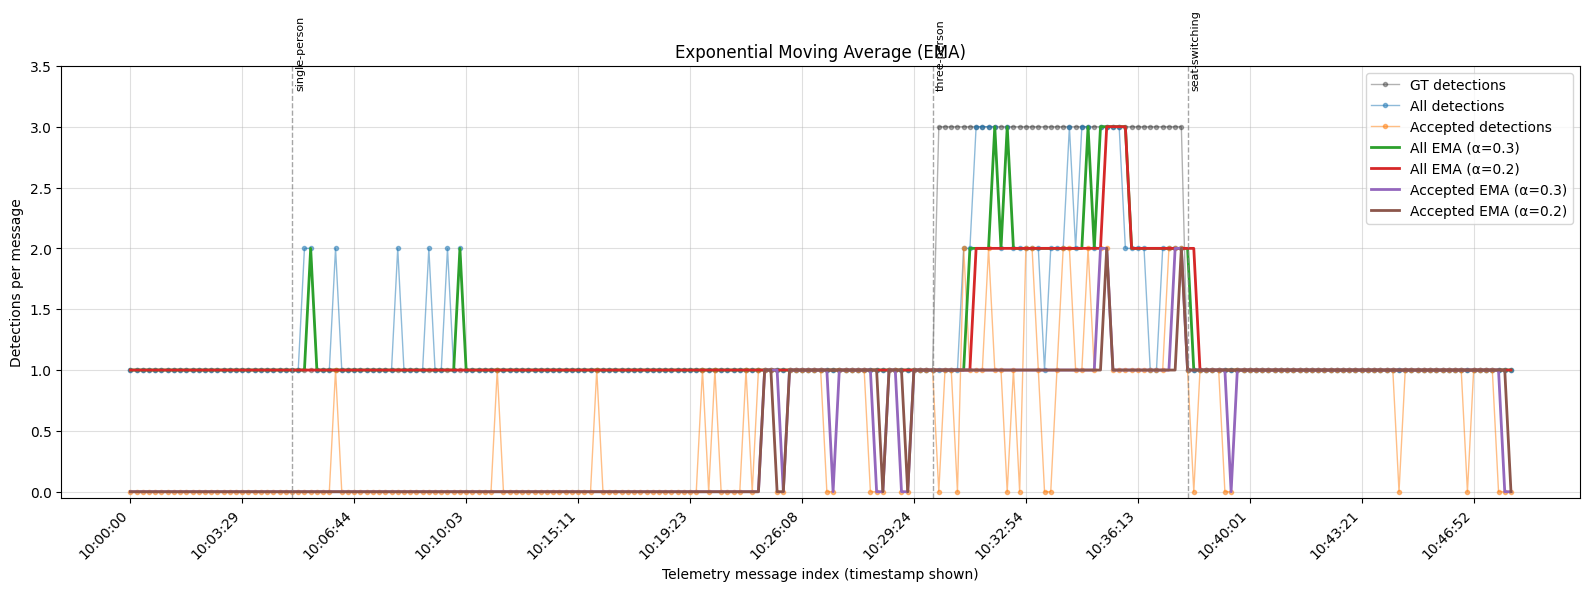

In [9]:
# ------------------------------------------------------------
# Exponential Moving Average (EMA)
# ------------------------------------------------------------
plt.figure(figsize=(16, 6))

x = np.arange(len(ts_msgs))
labels = ts_msgs["timestamp"].dt.strftime("%H:%M:%S").tolist()

# Base lines
plt.plot(x, ts_msgs["gt_value"], "k.-", alpha=0.3, label="GT detections", linewidth=1)
plt.plot(x, ts_msgs["all"], ".-", alpha=0.5, label="All detections", linewidth=1)
plt.plot(x, ts_msgs["detection"], ".-", alpha=0.5, label="Accepted detections", linewidth=1)

# Smoothed lines (alpha=0.3 ~= window 3, alpha=0.2 ~= window 5)
all_smooth_3 = np.round(common.ema(ts_msgs["all"].values, alpha=0.3)).astype(int)
all_smooth_5 = np.round(common.ema(ts_msgs["all"].values, alpha=0.2)).astype(int)
det_smooth_3 = np.round(common.ema(ts_msgs["detection"].values, alpha=0.3)).astype(int)
det_smooth_5 = np.round(common.ema(ts_msgs["detection"].values, alpha=0.2)).astype(int)

plt.plot(x, all_smooth_3, "-", linewidth=2, label="All EMA (α=0.3)")
plt.plot(x, all_smooth_5, "-", linewidth=2, label="All EMA (α=0.2)")
plt.plot(x, det_smooth_3, "-", linewidth=2, label="Accepted EMA (α=0.3)")
plt.plot(x, det_smooth_5, "-", linewidth=2, label="Accepted EMA (α=0.2)")

# Vertical split lines
base_date = ts_msgs["timestamp"].iloc[0].date()
splits = [
    (datetime.combine(base_date, common.ONE_PERSON_START).replace(tzinfo=ts_msgs["timestamp"].iloc[0].tzinfo), "single-person"),
    (datetime.combine(base_date, common.THREE_PERSONS_START).replace(tzinfo=ts_msgs["timestamp"].iloc[0].tzinfo), "three-person"),
    (datetime.combine(base_date, common.ONE_PERSON_CHAIRS_START).replace(tzinfo=ts_msgs["timestamp"].iloc[0].tzinfo), "seat-switching"),
]

ymax = 3.5
ts_series = ts_msgs["timestamp"].reset_index(drop=True)
for split_time, label in splits:
    diffs = (ts_series - split_time).abs()
    idx = int(diffs.idxmin())
    plt.axvline(idx, linestyle="--", linewidth=1, color="gray", alpha=0.7)
    plt.text(idx + 0.5, ymax - 0.2, label, rotation=90, va="bottom", ha="left", fontsize=8)

step = max(1, len(x) // 12)
plt.xticks(ticks=np.arange(0, len(x), step), labels=[labels[i] for i in range(0, len(x), step)], rotation=45, ha="right")
plt.xlabel("Telemetry message index (timestamp shown)")
plt.ylabel("Detections per message")
plt.title("Exponential Moving Average (EMA)")
plt.ylim(bottom=-0.05, top=ymax)
plt.legend(loc='upper right')
plt.grid(alpha=0.4)
plt.tight_layout()
plt.show()

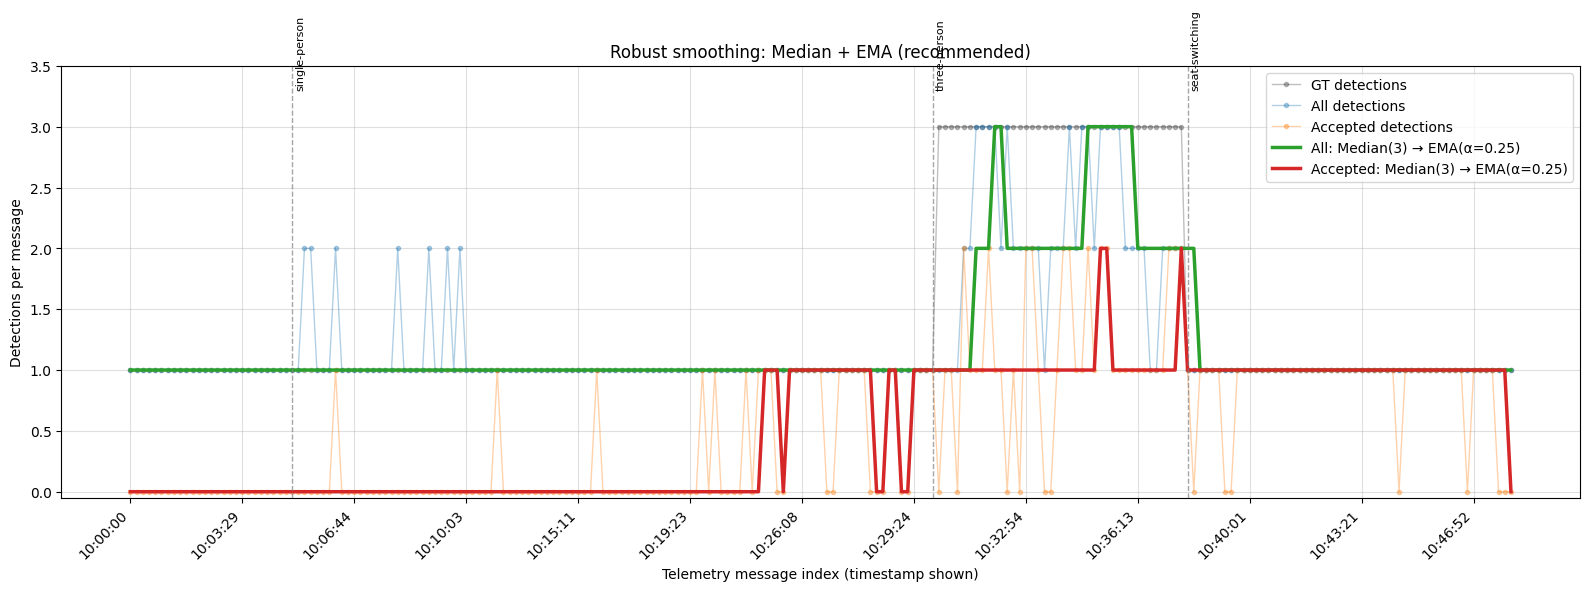

In [10]:
# ------------------------------------------------------------
# Robust smoothing: Median + EMA (recommended for step-like telemetry)
#   - Median removes impulse spikes (e.g., chair movement artifacts)
#   - EMA adds light temporal smoothing with low lag
# ------------------------------------------------------------

def robust_ema(x, median_window: int = 3, alpha: float = 0.25):
    x_med = common.median_filter(np.asarray(x, dtype=float), window=median_window)
    return common.ema(x_med, alpha=alpha)

def _split_indices_from_common(ts_msgs: pd.DataFrame):
    """Return [(idx, label), ...] split lines using times from common.py."""
    if "timestamp" not in ts_msgs.columns:
        return []
    ts = ts_msgs["timestamp"].reset_index(drop=True)
    if len(ts) == 0:
        return []
    base_date = ts.iloc[0].date()
    tz = ts.iloc[0].tzinfo

    splits = [
        (datetime.combine(base_date, common.ONE_PERSON_START).replace(tzinfo=tz), "single-person"),
        (datetime.combine(base_date, common.THREE_PERSONS_START).replace(tzinfo=tz), "three-person"),
        (datetime.combine(base_date, common.ONE_PERSON_CHAIRS_START).replace(tzinfo=tz), "seat-switching"),
    ]

    out = []
    for split_time, label in splits:
        idx = int((ts - split_time).abs().idxmin())
        out.append((idx, label))
    return out

plt.figure(figsize=(16, 6))

x = np.arange(len(ts_msgs))
labels = ts_msgs["timestamp"].dt.strftime("%H:%M:%S").tolist()

# Base lines
plt.plot(x, ts_msgs["gt_value"], "k.-", alpha=0.25, label="GT detections", linewidth=1)
plt.plot(x, ts_msgs["all"], ".-", alpha=0.35, label="All detections", linewidth=1)
plt.plot(x, ts_msgs["detection"], ".-", alpha=0.35, label="Accepted detections", linewidth=1)

# Robust smoothed lines
all_robust = np.round(robust_ema(ts_msgs["all"].values, median_window=3, alpha=0.25)).astype(int)
det_robust = np.round(robust_ema(ts_msgs["detection"].values, median_window=3, alpha=0.25)).astype(int)

plt.plot(x, all_robust, "-", linewidth=2.5, label="All: Median(3) → EMA(α=0.25)")
plt.plot(x, det_robust, "-", linewidth=2.5, label="Accepted: Median(3) → EMA(α=0.25)")

# Vertical split lines
ymax = max(3.5, float(np.nanmax(ts_msgs["all"].values)) + 0.5)
for idx, lab in _split_indices_from_common(ts_msgs):
    plt.axvline(idx, linestyle="--", linewidth=1, color="gray", alpha=0.7)
    plt.text(idx + 0.5, ymax - 0.2, lab, rotation=90, va="bottom", ha="left", fontsize=8)

step = max(1, len(x) // 12)
plt.xticks(
    ticks=np.arange(0, len(x), step),
    labels=[labels[i] for i in range(0, len(x), step)],
    rotation=45,
    ha="right",
)

plt.xlabel("Telemetry message index (timestamp shown)")
plt.ylabel("Detections per message")
plt.title("Robust smoothing: Median + EMA (recommended)")
plt.ylim(bottom=-0.05, top=ymax)
plt.legend(loc="upper right")
plt.grid(alpha=0.4)
plt.tight_layout()

# Optional: save for the markdown report
plt.savefig("plot_robust_median_ema.png", dpi=160, bbox_inches="tight")

plt.show()


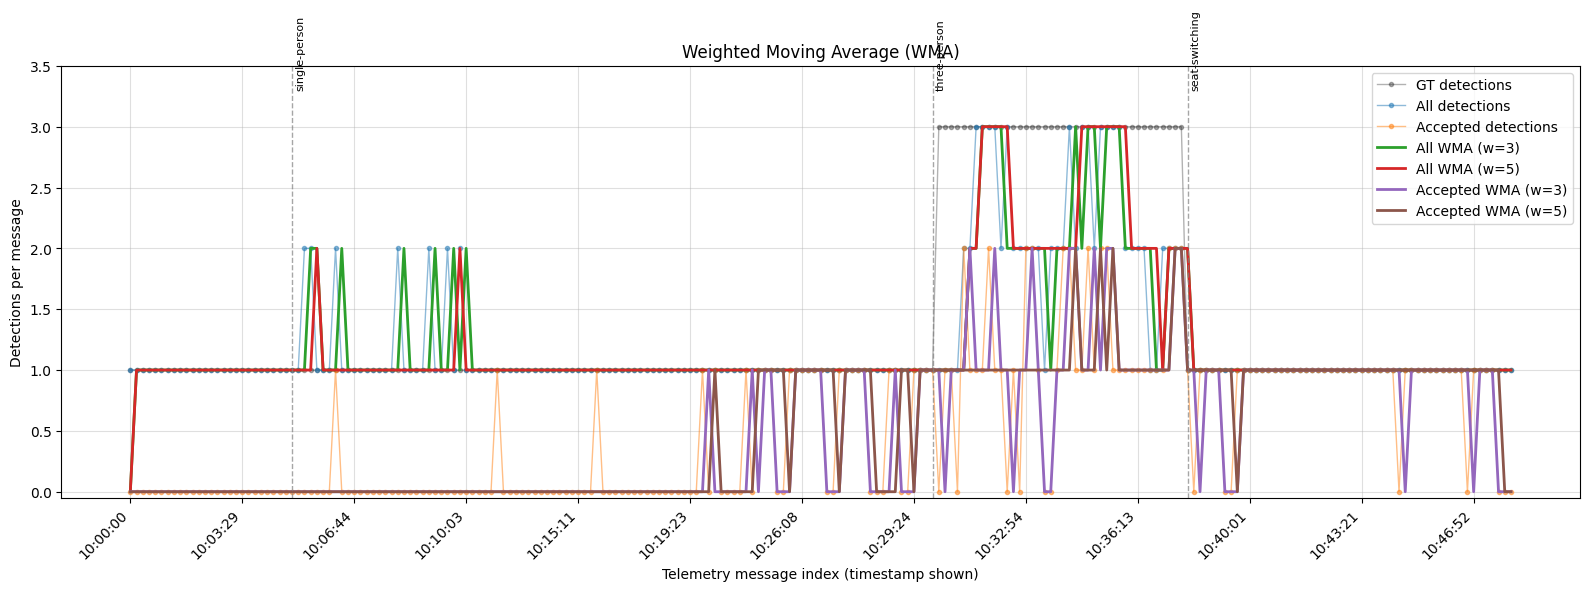

In [11]:
# ------------------------------------------------------------
# Weighted Moving Average (WMA)
# ------------------------------------------------------------
plt.figure(figsize=(16, 6))

x = np.arange(len(ts_msgs))
labels = ts_msgs["timestamp"].dt.strftime("%H:%M:%S").tolist()

# Base lines
plt.plot(x, ts_msgs["gt_value"], "k.-", alpha=0.3, label="GT detections", linewidth=1)
plt.plot(x, ts_msgs["all"], ".-", alpha=0.5, label="All detections", linewidth=1)
plt.plot(x, ts_msgs["detection"], ".-", alpha=0.5, label="Accepted detections", linewidth=1)

# Smoothed lines
all_smooth_3 = np.round(common.wma(ts_msgs["all"].values, window=3)).astype(int)
all_smooth_5 = np.round(common.wma(ts_msgs["all"].values, window=5)).astype(int)
det_smooth_3 = np.round(common.wma(ts_msgs["detection"].values, window=3)).astype(int)
det_smooth_5 = np.round(common.wma(ts_msgs["detection"].values, window=5)).astype(int)

plt.plot(x, all_smooth_3, "-", linewidth=2, label="All WMA (w=3)")
plt.plot(x, all_smooth_5, "-", linewidth=2, label="All WMA (w=5)")
plt.plot(x, det_smooth_3, "-", linewidth=2, label="Accepted WMA (w=3)")
plt.plot(x, det_smooth_5, "-", linewidth=2, label="Accepted WMA (w=5)")

# Vertical split lines
base_date = ts_msgs["timestamp"].iloc[0].date()
splits = [
    (datetime.combine(base_date, common.ONE_PERSON_START).replace(tzinfo=ts_msgs["timestamp"].iloc[0].tzinfo), "single-person"),
    (datetime.combine(base_date, common.THREE_PERSONS_START).replace(tzinfo=ts_msgs["timestamp"].iloc[0].tzinfo), "three-person"),
    (datetime.combine(base_date, common.ONE_PERSON_CHAIRS_START).replace(tzinfo=ts_msgs["timestamp"].iloc[0].tzinfo), "seat-switching"),
]

ymax = 3.5
ts_series = ts_msgs["timestamp"].reset_index(drop=True)
for split_time, label in splits:
    diffs = (ts_series - split_time).abs()
    idx = int(diffs.idxmin())
    plt.axvline(idx, linestyle="--", linewidth=1, color="gray", alpha=0.7)
    plt.text(idx + 0.5, ymax - 0.2, label, rotation=90, va="bottom", ha="left", fontsize=8)

step = max(1, len(x) // 12)
plt.xticks(ticks=np.arange(0, len(x), step), labels=[labels[i] for i in range(0, len(x), step)], rotation=45, ha="right")
plt.xlabel("Telemetry message index (timestamp shown)")
plt.ylabel("Detections per message")
plt.title("Weighted Moving Average (WMA)")
plt.ylim(bottom=-0.05, top=ymax)
plt.legend(loc='upper right')
plt.grid(alpha=0.4)
plt.tight_layout()
plt.show()

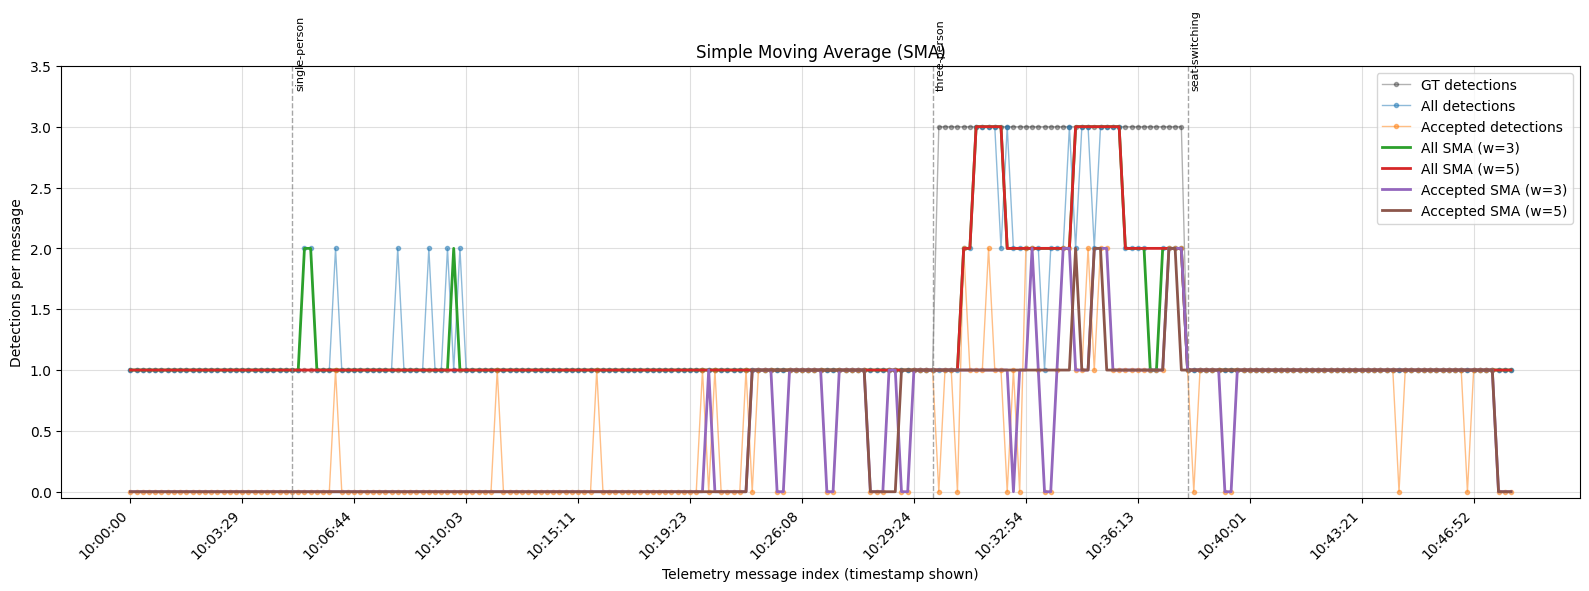

In [12]:
# ------------------------------------------------------------
# Simple Moving Average (SMA)
# ------------------------------------------------------------
plt.figure(figsize=(16, 6))

x = np.arange(len(ts_msgs))
labels = ts_msgs["timestamp"].dt.strftime("%H:%M:%S").tolist()

# Base lines
plt.plot(x, ts_msgs["gt_value"], "k.-", alpha=0.3, label="GT detections", linewidth=1)
plt.plot(x, ts_msgs["all"], ".-", alpha=0.5, label="All detections", linewidth=1)
plt.plot(x, ts_msgs["detection"], ".-", alpha=0.5, label="Accepted detections", linewidth=1)

# Smoothed lines
all_smooth_3 = np.round(common.sma(ts_msgs["all"].values, window=3)).astype(int)
all_smooth_5 = np.round(common.sma(ts_msgs["all"].values, window=5)).astype(int)
det_smooth_3 = np.round(common.sma(ts_msgs["detection"].values, window=3)).astype(int)
det_smooth_5 = np.round(common.sma(ts_msgs["detection"].values, window=5)).astype(int)

plt.plot(x, all_smooth_3, "-", linewidth=2, label="All SMA (w=3)")
plt.plot(x, all_smooth_5, "-", linewidth=2, label="All SMA (w=5)")
plt.plot(x, det_smooth_3, "-", linewidth=2, label="Accepted SMA (w=3)")
plt.plot(x, det_smooth_5, "-", linewidth=2, label="Accepted SMA (w=5)")

# Vertical split lines
base_date = ts_msgs["timestamp"].iloc[0].date()
splits = [
    (datetime.combine(base_date, common.ONE_PERSON_START).replace(tzinfo=ts_msgs["timestamp"].iloc[0].tzinfo), "single-person"),
    (datetime.combine(base_date, common.THREE_PERSONS_START).replace(tzinfo=ts_msgs["timestamp"].iloc[0].tzinfo), "three-person"),
    (datetime.combine(base_date, common.ONE_PERSON_CHAIRS_START).replace(tzinfo=ts_msgs["timestamp"].iloc[0].tzinfo), "seat-switching"),
]

ymax = 3.5
ts_series = ts_msgs["timestamp"].reset_index(drop=True)
for split_time, label in splits:
    diffs = (ts_series - split_time).abs()
    idx = int(diffs.idxmin())
    plt.axvline(idx, linestyle="--", linewidth=1, color="gray", alpha=0.7)
    plt.text(idx + 0.5, ymax - 0.2, label, rotation=90, va="bottom", ha="left", fontsize=8)

step = max(1, len(x) // 12)
plt.xticks(ticks=np.arange(0, len(x), step), labels=[labels[i] for i in range(0, len(x), step)], rotation=45, ha="right")
plt.xlabel("Telemetry message index (timestamp shown)")
plt.ylabel("Detections per message")
plt.title("Simple Moving Average (SMA)")
plt.ylim(bottom=-0.05, top=ymax)
plt.legend(loc='upper right')
plt.grid(alpha=0.4)
plt.tight_layout()
plt.show()

# Smoothing Review Report (Telemetry Detections)

## Objective
Compare smoothing methods for discrete, step-like telemetry signals (detections per message), focusing on:
- noise reduction
- robustness to outliers/spikes
- responsiveness to real step changes (e.g., 1 → 3 persons)
- suitability for online/near-real-time use (causality + low lag)

## Summary Recommendation
**Best overall for this signal:** **Median filter (small window) → EMA**
- **Median** removes impulsive spikes without blurring step edges too much.
- **EMA** adds stable smoothing with low lag and supports online updates.

## Comparison Table

| Method | Strengths | Weaknesses | Best Use |
|---|---|---|---|
| **SMA** (box) | Simple, predictable | Strong lag, smears steps | Baseline reference |
| **WMA** | Less lag than SMA | Still smears steps; parameter sensitive | Baseline / visualization |
| **EMA** | Low cost, causal, good trade-off | Still reacts to spikes | Online smoothing |
| **Gaussian** | Very clean curves | Non-causal (future leakage), blurs steps | Offline visualization |
| **Median** | Excellent spike rejection | Can flatten short real events | Pre-filter for robustness |
| **Savitzky–Golay** | Preserves curvature | Can mislead on counts/steps; tuning sensitive | Offline only (rare) |
| **LOWESS** | Smooth trend | Slow, less responsive locally | Trend visualization only |
| **Median → EMA** | Robust + responsive + causal | Needs 2 params (window, alpha) | **Recommended default** |

## Plots
- Existing plots show per-method behavior and trade-offs.
- Added plot: **Median(3) → EMA(α=0.25)**, saved as `plot_robust_median_ema.png` when the cell is executed.

> Tip for tuning:  
> - If you want **faster reaction** to changes: increase **α** (e.g., 0.30–0.45)  
> - If you have **more spikes**: increase median window to **5** (but watch for over-smoothing)

## Final Decision
Use **Median(3) → EMA(α=0.25)** as the default production smoothing for these signals.  
Maintain EMA-only as a fallback (or for very clean streams).  
Keep Gaussian/LOWESS/S-G for offline visualization, not for decision logic.
